# Figures
This notebook is structured to generate the figures in the publication. Some of the outputs used for the publication figures are in the output/publication directory. The code used to generate the data is provided in the main directory. You can follow instructions in `README.md` for instructions to regenerate the data. Make sure the output is not saved in the publication directory.

In [1]:
# Importing libraries

In [2]:
import matplotlib.pyplot as plt

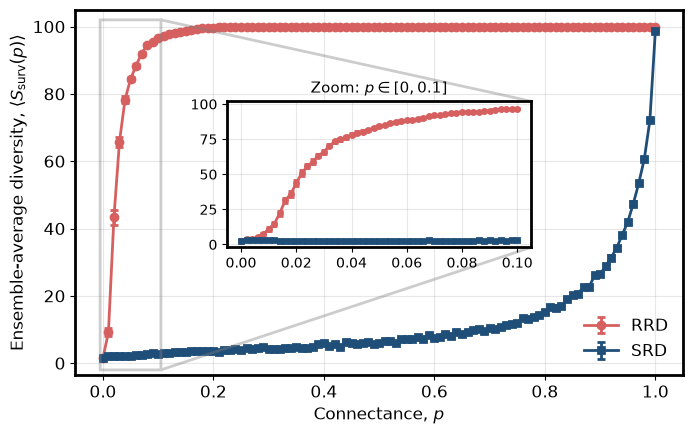

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Load both datasets
csv_full = "output/publication/simulation_results_full_withallspecies.csv"
csv_full = "output/publication/simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount101_betascale_50.0.csv"
csv_small = "output/publication/simulation_resultsSmall.csv"

try:
    df_full = pd.read_csv(csv_full)
    df_small = pd.read_csv(csv_small)
except FileNotFoundError as e:
    print(f"Error loading data: {e}")
    #exit()

# 2. Helper function to aggregate data
def aggregate_data(df):
    return df.groupby(["model", "p_link"]).agg(
        mean_survivors=('survivors', 'mean'),
        sem_survivors=('survivors', lambda x: x.sem(ddof=1) if len(x) > 1 else 0.0)
    ).reset_index()

sweep_full = aggregate_data(df_full)
sweep_small = aggregate_data(df_small)

# 3. Academic Formatting Definitions
notation_map = {"GLV": "SRD", "Bounded": "RRD"}
color_map = {"SRD": "#1f4e79", "RRD": "#d65f5f"}
marker_map = {"SRD": "s", "RRD": "o"}


# ---------------------------------------------------------
# Figure Setup (180mm = 7.09 inches width)
# ---------------------------------------------------------
fig, ax_main = plt.subplots(figsize=(7.09, 4.5))

# Create inset axes [x0, y0, width, height] in normalized axes coordinates
ax_inset = ax_main.inset_axes([0.25, 0.35, 0.50, 0.4])

# 4. Plotting Loop for both main and inset axes
for model_name in sweep_full['model'].unique():
    pub_name = notation_map.get(model_name, model_name)
    
    # Extract model data
    grp_full = sweep_full[sweep_full['model'] == model_name]
    grp_small = sweep_small[sweep_small['model'] == model_name]
    
    # Plot on Main Axis
    ax_main.errorbar(
        grp_full["p_link"], grp_full["mean_survivors"], yerr=grp_full["sem_survivors"],
        marker=marker_map[pub_name], color=color_map[pub_name],
        linestyle='-', capsize=3, lw=2.0, elinewidth=2.0, capthick=2.0, markersize=5, label=pub_name
    )
    
    # Plot on Inset Axis (must also obey 2pt line rule to avoid production delays)
    ax_inset.errorbar(
        grp_small["p_link"], grp_small["mean_survivors"], yerr=grp_small["sem_survivors"],
        marker=marker_map[pub_name], color=color_map[pub_name],
        linestyle='-', capsize=2, lw=2.0, elinewidth=2.0, capthick=2.0, markersize=3
    )

# ---------------------------------------------------------
# Formatting Main Axis
# ---------------------------------------------------------
# Applied your updated labels
ax_main.set_xlabel(r"Connectance, $p$")
ax_main.set_ylabel(r"Ensemble-average diversity, $\langle S_{\text{surv}}(p) \rangle$")
ax_main.grid(alpha=0.3)
ax_main.legend(loc='lower right', frameon=False)

# ---------------------------------------------------------
# Formatting Inset Axis
# ---------------------------------------------------------
ax_inset.set_xlim(-0.005, 0.105) 
ax_inset.set_ylim(-2, 102)
ax_inset.grid(alpha=0.3)
ax_inset.tick_params(axis='both', which='major', labelsize=10) # 10pt minimum for inset text
ax_inset.set_title(r"Zoom: $p \in [0, 0.1]$", fontsize=11)

# Subtle lines from main axis to inset
ax_main.indicate_inset_zoom(ax_inset, edgecolor="gray", alpha=0.4, linewidth=2.0)

plt.tight_layout()
plt.savefig("figures/Diversity_vs_Connectance_Combined.pdf", format="pdf", bbox_inches="tight")
plt.show()

Using alpha_scale files for p in [0, 1.0]:
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.01.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.02.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.025.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.05.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.075.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.1.csv
  simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_0.15.csv


/tmp/ipykernel_25988/498907888.py:186: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


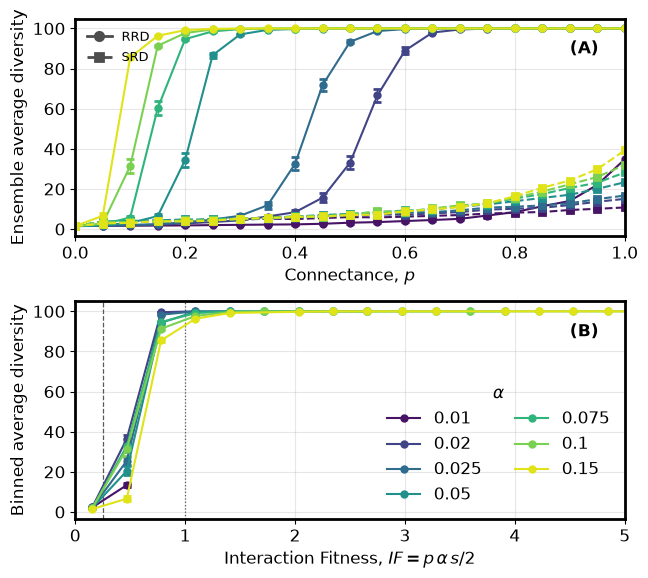

Saved figure to: figures/BRE_Diversity_and_Collapse_Combined.pdf
IF range: 0 to 7.5
Reference lines shown at IF = 0.25 and IF = 1.0


In [7]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def get_alpha_scale(path):
    match = re.search(r"alphascale_([-+]?\d*\.?\d+)\.csv$", path.name)
    if match is None:
        raise ValueError(f"Could not parse alpha_scale from {path.name}")
    return float(match.group(1))


requested_alpha_scales = {0.01, 0.02, 0.025, 0.05, 0.075, 0.1, 0.15}
s = 100

# Updated filename pattern to match the new p0-1_pcount21 dataset
csv_files = sorted(
    (
        path
        for path in Path(".").glob(
            "output/publication/simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount21_betascale_50.0_alphascale_*.csv"
        )
        if get_alpha_scale(path) in requested_alpha_scales
    ),
    key=get_alpha_scale,
)

if len(csv_files) != len(requested_alpha_scales):
    found = {get_alpha_scale(path) for path in csv_files}
    missing = sorted(requested_alpha_scales - found)
    raise FileNotFoundError(f"Missing alpha-scale files: {missing}")

print("Using alpha_scale files for p in [0, 1.0]:")
for csv_file in csv_files:
    print(f"  {csv_file.name}")

# Set up the figure with 2 rows, 1 column. 
fig, (ax_bre_p, ax_bre_if) = plt.subplots(
    2, 1, figsize=(7.09, 6.5), gridspec_kw={"hspace": 0.3}
)

colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(requested_alpha_scales)))
legend_handles_alpha = []
records = []

# ==========================================
# Loop 1: Top Panel (BRE & SRE vs connectance p)
# ==========================================
for csv_file, color in zip(csv_files, colors):
    alpha_scale = get_alpha_scale(csv_file)
    df = pd.read_csv(csv_file)

    # 1. Bounded Data Processing & Plotting
    bre = df[df["model"] == "Bounded"].copy()
    
    summary_bre = (
        bre.groupby("p_link")["survivors"]
        .agg(
            mean="mean",
            sem=lambda x: x.sem(ddof=1) if len(x) > 1 else 0.0,
        )
        .reset_index()
        .sort_values("p_link")
    )

    ax_bre_p.errorbar(
        summary_bre["p_link"], summary_bre["mean"], yerr=summary_bre["sem"],
        color=color, marker="o", markerfacecolor=color, markeredgecolor=color,
        markersize=4, linestyle="-", linewidth=1.5, capsize=3, elinewidth=0.9,
    )

    # 2. GLV (SRE) Data Processing & Plotting
    glv = df[df["model"] == "GLV"].copy()
    if not glv.empty:
        summary_glv = (
            glv.groupby("p_link")["survivors"]
            .agg(
                mean="mean",
                sem=lambda x: x.sem(ddof=1) if len(x) > 1 else 0.0,
            )
            .reset_index()
            .sort_values("p_link")
        )

        ax_bre_p.errorbar(
            summary_glv["p_link"], summary_glv["mean"], yerr=summary_glv["sem"],
            color=color, marker="s", markerfacecolor=color, markeredgecolor=color,
            markersize=4, linestyle="--", linewidth=1.5, capsize=3, elinewidth=0.9,
        )

    # 3. Save Bounded data for the bottom IF collapse panel
    bre["alpha_scale"] = alpha_scale
    bre["IF"] = bre["p_link"] * alpha_scale * s / 2.0
    bre["s1"] = bre["survivors"]
    records.append(bre[["alpha_scale", "p_link", "IF", "s1"]])

    legend_handles_alpha.append(
        Line2D(
            [], [], color=color, marker="o", linewidth=1.5, markersize=4,
            label=rf"${alpha_scale:g}$",
        )
    )

# ==========================================
# Loop 2: Bottom Panel (Collapsed BRE vs IF)
# ==========================================
collapse_data = pd.concat(records, ignore_index=True)
if_max = collapse_data["IF"].max()
bins = np.linspace(0.0, if_max, 25)
centers = 0.5 * (bins[:-1] + bins[1:])

for alpha_scale, color in zip(sorted(requested_alpha_scales), colors):
    group = collapse_data[collapse_data["alpha_scale"] == alpha_scale]
    bin_index = np.digitize(group["IF"], bins) - 1
    means = []
    errors = []
    valid_centers = []

    for bin_number, center in enumerate(centers):
        values = group.loc[bin_index == bin_number, "s1"]
        if len(values) == 0:
            continue
        means.append(values.mean())
        errors.append(values.sem() if len(values) > 1 else 0.0)
        valid_centers.append(center)

    ax_bre_if.errorbar(
        valid_centers, means, yerr=errors,
        color=color, marker="o", markersize=4,
        linewidth=1.5, capsize=3, elinewidth=0.9,
    )

# ==========================================
# Formatting and Export
# ==========================================
# Top panel formatting
ax_bre_p.set_ylabel("Ensemble average diversity")
ax_bre_p.set_xlabel(r"Connectance, $p$")
ax_bre_p.set_xlim(0, 1.0) # Expanded to 1.0 to accommodate new dataset
ax_bre_p.grid(alpha=0.3)

ax_bre_p.text(
    0.9, 0.9, "(A)", transform=ax_bre_p.transAxes,
    ha="left", va="top", fontweight="bold"
)

# Add custom model legend to the top panel
model_legend = [
    Line2D([0], [0], color="0.3", marker="o", linestyle="-", label="RRD"),
    Line2D([0], [0], color="0.3", marker="s", linestyle="--", label="SRD")
]
ax_bre_p.legend(
    handles=model_legend,
    frameon=False,
    loc="upper left",
    fontsize=9
)

# Bottom panel formatting
ax_bre_if.set_ylabel("Binned average diversity")
ax_bre_if.set_xlabel(r"Interaction Fitness, $IF = p\,\alpha\,s/2$")
ax_bre_if.grid(alpha=0.3)
ax_bre_if.axvline(0.25, color="0.35", linestyle="--", linewidth=0.9)
ax_bre_if.axvline(1.0, color="0.35", linestyle=":", linewidth=0.9)

ax_bre_if.set_xlim(0,5)
# Alpha color legend
ax_bre_if.legend(
    handles=legend_handles_alpha,
    title=r"$\alpha$",
    frameon=False,
    ncol=2,
    fontsize=12,
    loc="lower right",
)

ax_bre_if.text(
    0.9, 0.9, "(B)", transform=ax_bre_if.transAxes,
    ha="left", va="top", fontweight="bold"
)

fig.tight_layout()

output_file = "figures/BRE_Diversity_and_Collapse_Combined.pdf"
fig.savefig(output_file, bbox_inches="tight")
fig.savefig("figures/BRE_Diversity_and_Collapse_Combined.png", bbox_inches="tight")

plt.show()

print(f"Saved figure to: {output_file}")
print(f"IF range: {collapse_data['IF'].min():.4g} to {collapse_data['IF'].max():.4g}")
print("Reference lines shown at IF = 0.25 and IF = 1.0")

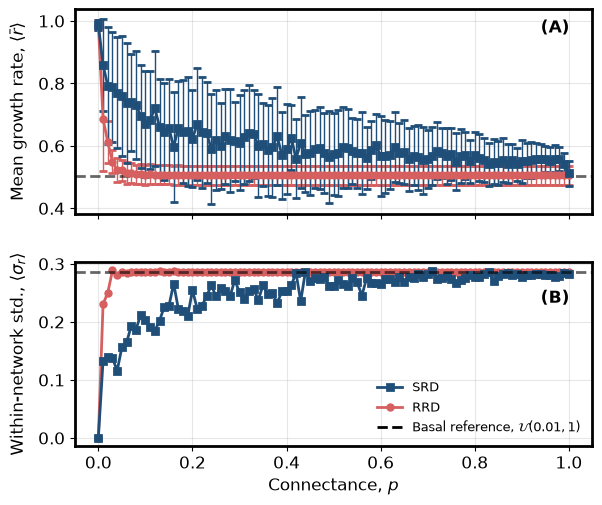

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast
from matplotlib.lines import Line2D

# 1. Enforce Frontiers Style Guidelines Globally
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 2.0,
    'lines.linewidth': 2.0,
    'lines.markeredgewidth': 2.0,
    'errorbar.capsize': 3.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# 2. Load the data
#csv_filename = "output/publication/simulation_results_full_withallspecies.csv"
csv_filename = "output/publication/simulation_results_full_withallspecies_N100_T2000_c1_r0.01-1_threshold0.0001_reps50_p0-1_pcount101_betascale_50.0.csv"

try:
    df = pd.read_csv(csv_filename)
except FileNotFoundError:
    print(f"Error: {csv_filename} not found. Please ensure the main script has run.")

# --- Data Processing: Mean ---
summary_r = df.groupby(["model", "p_link"]).agg(
    avg_mean_r=('mean_r_survivors', 'mean'),
    std_mean_r=('mean_r_survivors', 'std')
).reset_index()
population_mean_r = (0.01 + 1.0) / 2.0

# --- Data Processing: Standard Deviation ---
if 'r_survivors_list' in df.columns:
    df['r_survivors_list'] = df['r_survivors_list'].apply(ast.literal_eval)
elif 'r_list' in df.columns and 'survivors_mask' in df.columns:
    df['r_list'] = df['r_list'].apply(ast.literal_eval)
    df['survivors_mask'] = df['survivors_mask'].apply(ast.literal_eval)
    df['r_survivors_list'] = df.apply(
        lambda row: np.array(row['r_list'])[np.array(row['survivors_mask'])], axis=1
    )

df['std_r_survivors'] = df['r_survivors_list'].apply(
    lambda x: np.std(x, ddof=1) if len(x) > 1 else 0.0
)

summary_std = df.groupby(["model", "p_link"]).agg(
    avg_std_r=('std_r_survivors', 'mean')
).reset_index()

r_min, r_max = 0.01, 1.0
population_std_r = (r_max - r_min) / np.sqrt(12)

# 3. Academic Formatting Definitions
notation_map = {"GLV": "SRD", "Bounded": "RRD"}
color_map = {"SRD": "#1f4e79", "RRD": "#d65f5f"}
marker_map = {"SRD": "s", "RRD": "o"}

# 4. Compact two-panel figure
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(7.09, 5.2),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 0.9]}
)

# --- Panel (A): Mean Intrinsic Growth Rate ---
for model_name, grp in summary_r.groupby("model"):
    pub_name = notation_map.get(model_name, model_name)
    ax1.errorbar(
        grp["p_link"], grp["avg_mean_r"], yerr=grp["std_mean_r"],
        marker=marker_map[pub_name], color=color_map[pub_name],
        linestyle='-', capsize=3, lw=2.0, elinewidth=1.0, capthick=2.0,
        markersize=4
    )

ax1.axhline(population_mean_r, color='black', linestyle='--', linewidth=2.0, alpha=0.6)
ax1.set_ylabel(r"Mean growth rate, $\langle \bar{r} \rangle$", labelpad=8)
ax1.grid(alpha=0.3)
ax1.text(
    0.9, 0.95, "(A)", transform=ax1.transAxes,
    ha="left", va="top", fontweight="bold"
)

# --- Panel (B): Standard Deviation of Intrinsic Growth Rate ---
for model_name, grp in summary_std.groupby("model"):
    pub_name = notation_map.get(model_name, model_name)
    ax2.plot(
        grp["p_link"], grp["avg_std_r"],
        marker=marker_map[pub_name], color=color_map[pub_name],
        linestyle='-', lw=2.0, markersize=4
    )

ax2.axhline(population_std_r, color='black', linestyle='--', linewidth=2.0, alpha=0.6)
ax2.set_xlabel(r"Connectance, $p$")
ax2.set_ylabel(r"Within-network std., $\langle \sigma_r \rangle$", labelpad=8)
ax2.grid(alpha=0.3)
ax2.text(
    0.9, 0.85, "(B)", transform=ax2.transAxes,
    ha="left", va="top", fontweight="bold"
)

model_handles = [
    Line2D([], [], color=color_map[name], marker=marker_map[name], lw=2,
           markersize=4, label=name)
    for name in ("SRD", "RRD")
]
reference_handle = Line2D(
    [], [], color="black", linestyle="--", lw=2,
    label=r"Basal reference, $\mathcal{U}(0.01, 1)$"
)
ax2.legend(
    handles=model_handles + [reference_handle],
    loc="lower right",
    frameon=False,
    fontsize=9,
    handlelength=2.0
)
#ax1.set_ylim(0.3,1.)
fig.subplots_adjust(left=0.25, right=0.98, bottom=0.13, top=0.97, hspace=0.25)
fig.savefig("figures/Combined_Mean_and_STD_vs_p.pdf", format="pdf", bbox_inches="tight")
plt.show()

Analyzing ensemble for p_link = [np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.05)]


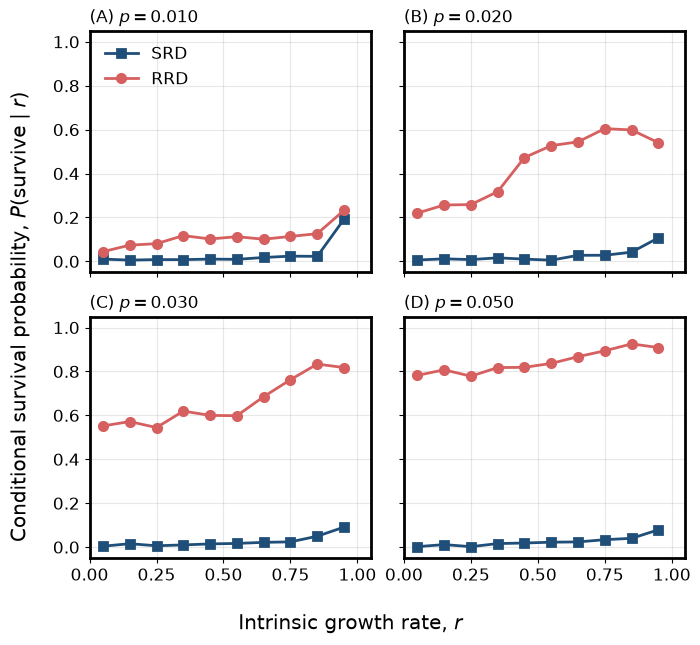

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

# 1. Enforce Frontiers Style Guidelines Globally
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 2.0,
    'lines.linewidth': 2.0,
    'lines.markeredgewidth': 2.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# 2. Configuration
csv_filename = "output/publication/simulation_results_full_withallspecies.csv"
target_p_links = [0.01, 0.02, 0.03, 0.05]
num_bins = 10

# Academic Formatting Definitions
notation_map = {"GLV": "SRD", "Bounded": "RRD"}
color_map = {"SRD": "#1f4e79", "RRD": "#d65f5f"}
marker_map = {"SRD": "s", "RRD": "o"}

# 3. Load and filter data efficiently
try:
    df = pd.read_csv(csv_filename)
except FileNotFoundError:
    print(f"Error: {csv_filename} not found. Please ensure the main script has run.")
    #exit()

# Find the closest p_links in the dataset to our targets
available_ps = df['p_link'].unique()
closest_ps = [available_ps[np.argmin(np.abs(available_ps - t))] for t in target_p_links]

# Filter dataset BEFORE evaluating strings to drastically speed up execution
df_filtered = df[df['p_link'].isin(closest_ps)].copy()
print(f"Analyzing ensemble for p_link = {closest_ps}")

# Safely evaluate the stringified lists only on the necessary rows
df_filtered['r_list'] = df_filtered['r_list'].apply(ast.literal_eval)
df_filtered['survivors_mask'] = df_filtered['survivors_mask'].apply(ast.literal_eval)

# 4. Figure Setup (180mm = 7.09 inches width)
fig, axes = plt.subplots(2, 2, figsize=(7.09, 6.5), sharex=True, sharey=True)
axes = axes.flatten()

r_bins = np.linspace(0, 1.0, num_bins + 1)
bin_centers = (r_bins[:-1] + r_bins[1:]) / 2
panel_labels = ['A', 'B', 'C', 'D']

# 5. Plotting Loop for Grid
for idx, (target_p, ax) in enumerate(zip(closest_ps, axes)):
    df_p = df_filtered[df_filtered['p_link'] == target_p]
    
    for model in ["GLV", "Bounded"]:
        df_model = df_p[df_p['model'] == model]
        pub_name = notation_map[model]
        
        # Flatten the ensemble data into single continuous arrays
        all_r = np.concatenate(df_model['r_list'].values)
        all_survivors = np.concatenate(df_model['survivors_mask'].values)
        
        # Count total and surviving species in each r bin
        counts_total, _ = np.histogram(all_r, bins=r_bins)
        surviving_r = all_r[all_survivors]
        counts_survived, _ = np.histogram(surviving_r, bins=r_bins)
        
        # Calculate P(survive | r), handling division by zero
        prob_survive = np.divide(
            counts_survived, counts_total, 
            out=np.zeros_like(counts_total, dtype=float), 
            where=counts_total != 0
        )
        
        # Add legend labels only to the first subplot to prevent duplication
        ax.plot(
            bin_centers, prob_survive, 
            marker=marker_map[pub_name], color=color_map[pub_name], 
            linestyle='-', linewidth=2.0, markersize=6, 
            label=pub_name if idx == 0 else ""
        )

    # Format Individual Subplots
    ax.set_title(f"({panel_labels[idx]}) $p = {target_p:.3f}$", loc='left', fontsize=12)
    ax.grid(alpha=0.3)
    ax.set_xlim(0.0, 1.05)
    ax.set_ylim(-0.05, 1.05)
    #ax.set_yscale("log")

# 6. Global Formatting and Export
# Set unified axis labels for the whole grid
fig.supxlabel(r"Intrinsic growth rate, $r$")
fig.supylabel(r"Conditional survival probability, $P(\text{survive} \mid r)$")

# Add the legend to the first panel
axes[0].legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig("figures/Conditional_Survival_Prob_2x2.pdf", format="pdf", bbox_inches="tight")
plt.show()

# Figure 5 code in `exploring_topologies.ipynb`